In [1]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    x = torch.randn(1000, 1000, device="cuda")
    y = x @ x

    print("GPU 연산 성공:", y.shape)

PyTorch: 2.14.1+cu132
Torchvision: 0.29.1+cu132
CUDA: 13.2
CUDA Available: True
GPU: NVIDIA GeForce RTX 5060 Ti
GPU 연산 성공: torch.Size([1000, 1000])


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path('../data')

train_df = pd.read_csv(DATA_DIR/'train.csv')

print("데이터 크기:", train_df.shape)
display(train_df.head())

데이터 크기: (18632, 2)


,image,labels
0,800113bb65efe69e.jpg,healthy
1,8002cb321f8bfcdf.jpg,scab frog_eye_leaf_spot complex
2,80070f7fb5e2ccaa.jpg,scab
3,80077517781fb94f.jpg,scab
4,800cbf0ff87721f8.jpg,complex


In [3]:
train_df['labels'].value_counts()

labels
scab                               4826
healthy                            4624
frog_eye_leaf_spot                 3181
rust                               1860
complex                            1602
powdery_mildew                     1184
scab frog_eye_leaf_spot             686
scab frog_eye_leaf_spot complex     200
frog_eye_leaf_spot complex          165
rust frog_eye_leaf_spot             120
rust complex                         97
powdery_mildew complex               87
Name: count, dtype: int64

In [4]:
train_df["labels_count"] = train_df["labels"].str.split().str.len()

print(train_df['labels_count'].value_counts().sort_index())

labels_count
1    17277
2     1155
3      200
Name: count, dtype: int64


In [5]:
labels = train_df['labels'].str.split()

labels = labels.explode()

label_counts = labels.value_counts()

display(label_counts)

labels
scab                  5712
healthy               4624
frog_eye_leaf_spot    4352
complex               2151
rust                  2077
powdery_mildew        1271
Name: count, dtype: int64

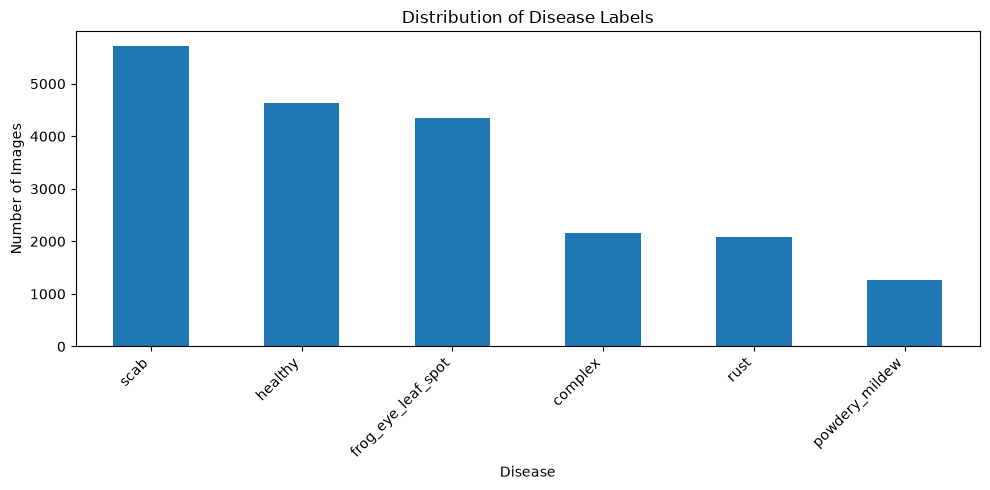

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

label_counts.plot(kind = 'bar')

plt.title("Distribution of Disease Labels")
plt.xlabel('Disease')
plt.ylabel('Number of Images')
plt.xticks(rotation = 45, ha = 'right')

plt.tight_layout()
plt.show()

In [7]:
# 왜 복수 복수 라벨 문제에서 softmax보다 sigmoid가 더 적합할까?


# softmax는 여러 클래스 사이의 상대적인 확률을 계산하고,
# sigmoid는 각 클래스에 대한 독립적인 확률을 계산하기 때문

# softmax는 분모에 모든 클래스의 지수값을 더한다는 것
# 따라서 한 클래스의 확률이 증가하면 다른 클래스에 배분할 수 있는 확률이 줄어듦
# 즉 클래스들이 서로 경쟁하는 구조


# 사과 잎 한 장에서 Scab과 Rust가 동시에 발생할 수 있음
# 두 질병이 모두 존재할 확률이 높아야 하는데, Softmax에서는 클래스 별 확률의 합을 1로 제한
# 이 문제를 질병별 독립 예측으로 표현하기 어려움


# sigmoid
# 각 출력값에 개별적으로 적용
# sigmoid는 0 또는 1을 바로 출력하는 것이 아니라 0과 1 사이의 연속적인 값을 출력
# 그 결과를 0.5같은 Threshold와 비교해서 최종적으로 0 또는 1로 판단

# 왜 단일 라벨 데이터가 많으면 복수 라벨 예측이 어려울까?

# 모델이 하나의 라벨만 예측하는 방향으로 편향될 수 있음
# 모델이 두 질병을 동시에 예측하는 사례를 상대적으로 적게 경험을 함
# 다만, 복수 라벨 데이터가 적다고 해서 복수 라벨 예측 자체가 불가능 한 것은 아니다.

# 소수의 복합 질병 사례를 충분히 학습하지 못 할 수 있다.
# 가설 : 단일 라벨 이미지에 비해 복수 라벨 이미지에서 Recall이 낮게 나타날 것이다.

# 클래스 불균형이 심하면 Accuracy가 왜 위험할까?
# 클래스 불균형이 존재한다면 Accuracy만 볼 것이 아니라, Precision, Recall, F1-score등을 함께 확인


In [8]:
max_count = label_counts.max()
min_count = label_counts.min()

print("최대 클래스:", label_counts.idxmax(), max_count)
print("최소 클래스:", label_counts.idxmin(), min_count)
print("불균형 비율:", max_count / min_count)


최대 클래스: scab 5712
최소 클래스: powdery_mildew 1271
불균형 비율: 4.4940991345397325


In [9]:
label_ratio = label_counts / len(train_df) * 100

display(label_ratio)

labels
scab                  30.656934
healthy               24.817518
frog_eye_leaf_spot    23.357664
complex               11.544654
rust                  11.147488
powdery_mildew         6.821597
Name: count, dtype: float64

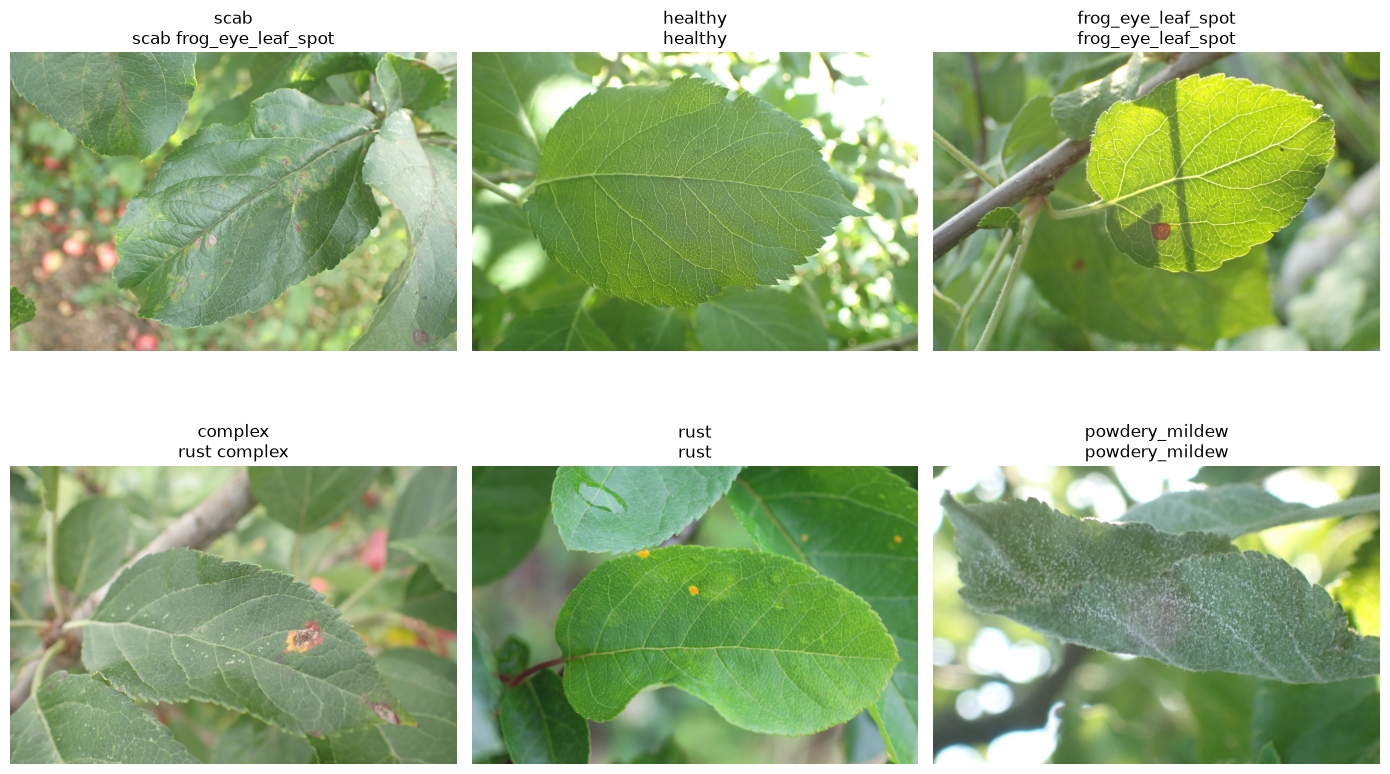

In [10]:
# 실제 이미지 확인

from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize = (14, 9))

for ax, label in zip(axes.flat, label_counts.index):
    sample = train_df[
        train_df["labels"].str.split().apply(lambda x: label in x)
        ].sample(1, random_state=42).iloc[0]

    image_path = DATA_DIR / "train_images" / sample["image"]
    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)
    ax.set_title(f"{label}\n{sample['labels']}")
    ax.axis('off')

plt.tight_layout()
plt.show()

In [11]:
# 원본 이미지가 어떤 크기인지 확인

from PIL import Image
from collections import Counter

image_sizes = []

for image_name in train_df['image']:
    image_path = DATA_DIR / "train_images"/ image_name


    with Image.open(image_path) as img:
        image_sizes.append(img.size)

size_counts = Counter(image_sizes)

print("이미지 크기 종류:", len(size_counts))
print('가장 많은 이미지 크기:')
print(size_counts.most_common(10))

이미지 크기 종류: 9
가장 많은 이미지 크기:
[((4000, 2672), 16485), ((2592, 1728), 1027), ((4000, 3000), 665), ((5184, 3456), 193), ((4032, 3024), 132), ((4608, 3456), 123), ((3024, 4032), 3), ((3024, 3024), 3), ((4000, 2248), 1)]


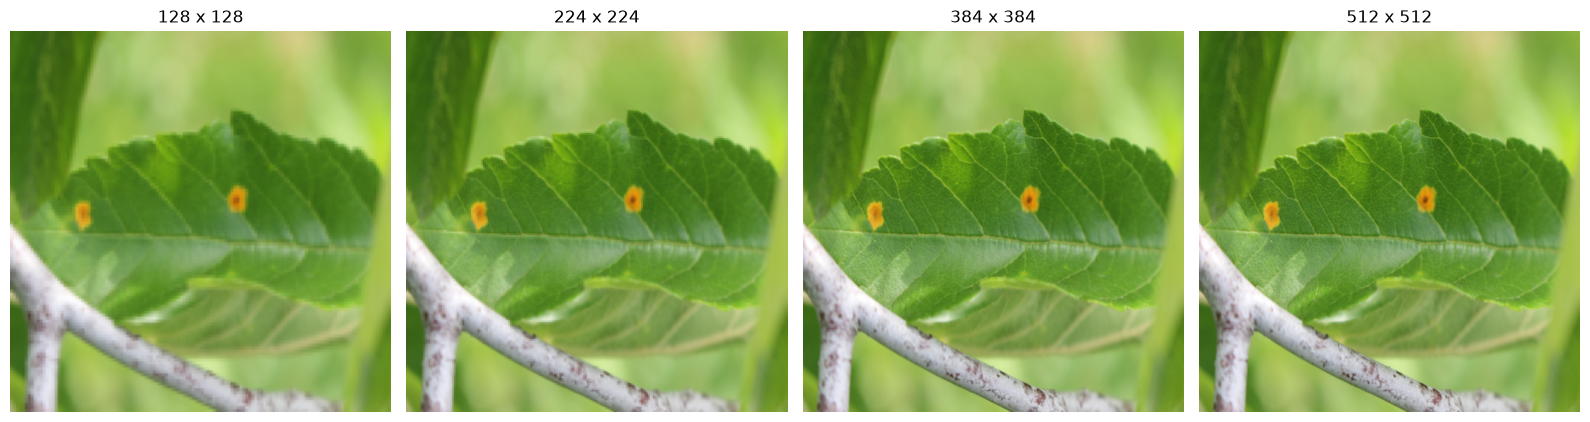

In [12]:
# 실제 Resize 결과 비교

from torchvision import transforms
import matplotlib.pyplot as plt
from PIL import Image

sample = train_df[
    train_df['labels'] == 'rust'
].iloc[0]

image_path = DATA_DIR / "train_images" / sample['image']
image = Image.open(image_path).convert("RGB")

sizes = [128, 224, 384, 512]

fig, axes = plt.subplots(1, 4, figsize = (16, 5))

for ax, size in zip(axes, sizes):
    transform = transforms.Resize((size, size))
    resized = transform(image)

    ax.imshow(resized)
    ax.set_title(f"{size} x {size}")
    ax.axis('off')

plt.tight_layout()
plt.show()

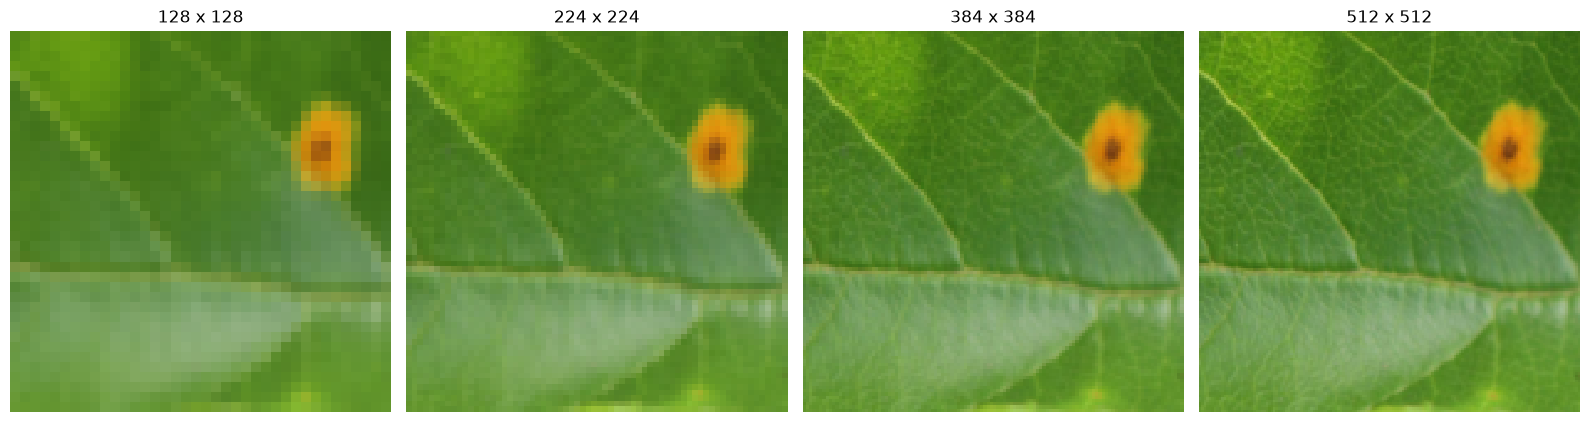

In [13]:
# 작은 질병 반점이 Resize 과정에서 얼마나 손실되는지 확인

from torchvision import transforms
import matplotlib.pyplot as plt

sizes = [128, 224, 384, 512]

fig, axes = plt.subplots(1, 4, figsize = (16, 5))

for ax, size in zip(axes, sizes):
    transform = transforms.Resize((size, size))
    resized = transform(image)

    w, h = resized.size

    cropped = resized.crop((
        w * 0.35,
        h * 0.35,
        w * 0.65,
        w * 0.65,
    ))

    ax.imshow(cropped, interpolation="nearest")
    ax.set_title(f"{size} x {size}")
    ax.axis('off')

plt.tight_layout()
plt.show()

In [14]:
# 데이터셋을 분할하고, 두 데이터셋의 개별 질병 분포가 얼마나 다른지 직접 확인

from sklearn.model_selection import train_test_split

train_data, valid_data = train_test_split(
    train_df,
    test_size = 0.2,
    random_state = 42,
    shuffle = True
)

print("Train:", train_data.shape)
print("Valid:", valid_data.shape)

Train: (14905, 3)
Valid: (3727, 3)


In [15]:
train_counts = (
    train_data["labels"]
    .str.split()
    .explode()
    .value_counts()
)

valid_counts = (
    valid_data["labels"]
    .str.split()
    .explode()
    .value_counts()
)

train_ratio = train_counts / len(train_data) * 100
valid_ratio = valid_counts / len(valid_data) * 100

distribution = pd.DataFrame({
    "Train (%)": train_ratio,
    "Valid (%)": valid_ratio
}).fillna(0)

distribution['Difference (%p)'] = (
    distribution["Train (%)"] - distribution["Valid (%)"]
).abs()

display(distribution.round(2))

,Train (%),Valid (%),Difference (%p)
labels,,,
scab,30.86,29.84,1.03
healthy,24.56,25.87,1.31
frog_eye_leaf_spot,23.38,23.26,0.12
complex,11.65,11.13,0.51
rust,11.16,11.08,0.08
powdery_mildew,6.84,6.76,0.08


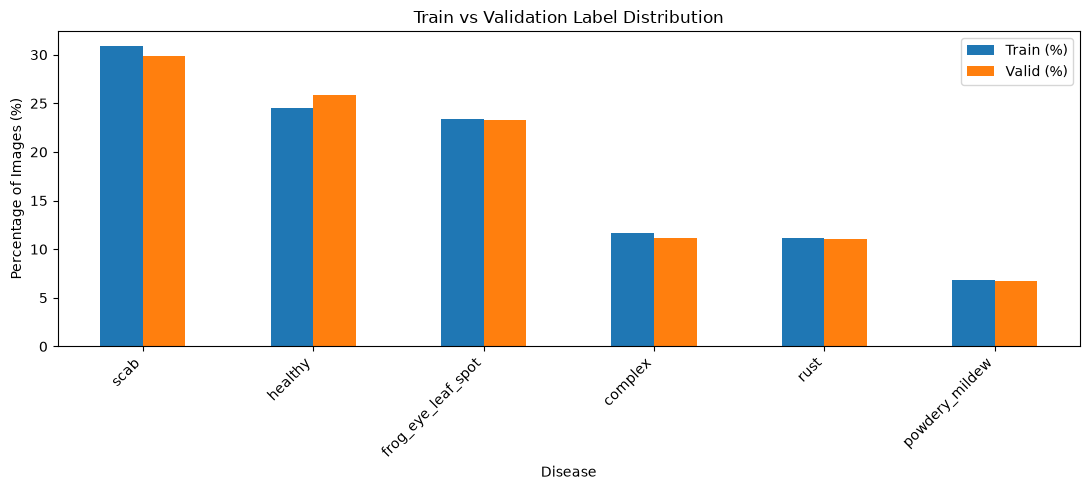

In [16]:
distribution[["Train (%)", "Valid (%)"]].plot(
    kind = "bar",
    figsize = (11, 5)
)

plt.title("Train vs Validation Label Distribution")
plt.xlabel("Disease")
plt.ylabel("Percentage of Images (%)")
plt.xticks(rotation = 45, ha = "right")

plt.tight_layout()
plt.show()

In [17]:
# 복수 라벨 이미지 비율

train_multi_ratio = (
    (train_data['labels'].str.split().str.len() > 1).mean() * 100
)

valid_multi_ratio = (
    (valid_data["labels"].str.split().str.len() > 1).mean() * 100
)

print(f"Train 복수 라벨 비율: {train_multi_ratio:.2f}%")
print(f"Valid 복수 라벨 비율: {valid_multi_ratio:.2f}%")

Train 복수 라벨 비율: 7.34%
Valid 복수 라벨 비율: 7.00%


In [18]:
# Train/ Validation 분포 분석

# 1. 모든 클래스에서 비율 차이가 약 1.31% 이하여서 분포가 비슷
# 2. 가장 적은 Powdery mildew도 validation 데이터에 충분한 수가 포함되어 있음

# 복수 라벨 이미지 비율

# 1. 복수 라벨 이미지가 validation에 지나치게 적게 들어가는 문제도 크게 나타나지 않음

# stratified Split을 해야 할까?

# 1. 현재 Random Split을 Baseline 검증용으로 유지
# 2. 현재 데이터 분포만 놓고 보면 큰 불균형이 발견되지 않았기 때문

In [19]:
# 데이터 누수 확인
# 모델이 Train에서 이미 봤던 잎과 거의 동일한 이미지를 Validation에서 만난다면, 검증 성능이 실제 새로운 잎에 대한 성능보다 높게 나올 수 있음

# 1. CSV와 파일명 중복 확인

print("전체 이미지:", len(train_df))
print("중복 이미지 이름:", train_df["image"].duplicated().sum())

common_images = set(train_data["image"]) & set(valid_data["image"])

print("Train / Valid 공통 이미지:", len(common_images))

전체 이미지: 18632
중복 이미지 이름: 0
Train / Valid 공통 이미지: 0


In [20]:
# 2. 이미지 내용이 완전히 같은지 확인
# SHA-256은 파일의 내용을 일정한 길이의 해시값으로 변환하는 함수
# 같은 내용의 파일은 같은 해시값을 갖게 되므로, 중복 파일을 차즌 데 사용할 수 있다.

import hashlib

def get_file_hash(image_path):
    sha256 = hashlib.sha256()

    with open(image_path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()



train_hashes = {}

for image_name in train_data["image"]:
    image_path = DATA_DIR / "train_images" / image_name
    train_hashes[image_name] = get_file_hash(image_path)

valid_hashes = {}

for image_name in valid_data["image"]:
    image_path = DATA_DIR / "train_images" / image_name
    valid_hashes[image_name] = get_file_hash(image_path)

common_hashes = set(train_hashes.values()) & set(valid_hashes.values())

print("완전히 동일한 파일 해시 개수:", len(common_hashes))

완전히 동일한 파일 해시 개수: 12


In [21]:
# 이미지가 거의 동일한 경우 찾기

!pip install ImageHash

In [22]:
import imagehash
from PIL import Image
# Perceptual Hash(phash)를 사용
# 일반적인 SHA-256과 달리 pHash는 이미지의 시각적인 특징을 기반으로 해시를 계산
# 같은 이미지를 조금 resized 하거나 압춘한 경우에도 비슷한 해시값이 나올 수 있음
# 다만 서로 다른 이미지인데도 비슷한 해시가 나올 수  있으므로, phash는 중복을 확정하는 도구가 아니라, 유사 이미지 후보를 찾는 도구


def get_phash(image_path):
    with Image.open(image_path) as img:
        return imagehash.phash(img.convert("RGB"))


# 각 이미지의 pHash를 계산
from tqdm.auto import tqdm

hash_records = []

for image_name in tqdm(train_df["image"]):
    image_path = DATA_DIR / "train_images" / image_name

    hash_records.append({
        'image': image_name,
        'phash': str(get_phash(image_path))
    })

hash_df = pd.DataFrame(hash_records)

c:\Users\SSAFY\Desktop\ParkJaeWon\AI-practice\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 18632/18632 [15:24<00:00, 20.15it/s]


In [23]:
train_phash = train_data[['image']].merge(
    hash_df,
    on = 'image'
)

valid_phash = valid_data[['image']].merge(
    hash_df,
    on = 'image'
)

same_phash = train_phash.merge(
    valid_phash,
    on = 'phash',
    suffixes = ("_train", "_valid")
)

print("pHash가 동일한 이미지 쌍:", len(same_phash))

display(same_phash.head(10))

pHash가 동일한 이미지 쌍: 12


,image_train,phash,image_valid
0,cdf892b5b4865859.jpg,82ba3e933947b097,82ba3e933947b097.jpg
1,d2d9c2bca7a72458.jpg,d1dec0973c2cf4a1,d1dec0973c2cf4a1.jpg
2,c9d63696629107ed.jpg,c9d63696629107ed,8f5263c61a8cdbe2.jpg
3,dbee22785d9285c4.jpg,c5aff2e545d0a129,c5aff2e545d0a129.jpg
4,e83f715e56462a31.jpg,d0c766bc38e1978c,d0c766bc38e1978c.jpg
5,d3945c098edc9dd1.jpg,dea33c5c0347aa4d,dea33c5c0347aa4d.jpg
6,aa0e969518e15d3f.jpg,bb1891fa8c61e663,bb1891fa8c61e663.jpg
7,f90738a0d2f2c1db.jpg,f90738a0d2f2c1db,bd8088cdad5f65e0.jpg
8,eec64e8cf1c8d0c6.jpg,e51690d8ad307dcb,e51690d8ad307dcb.jpg
9,8c0731fff680c51e.jpg,df90901ccb664de6,df90901ccb664de6.jpg


In [24]:
# 현재 결과가 의미하는 것 
# SHA-256은 파일의 내용을 기준으로 계산하기 때문에 Train과 Validation에 완전히 같은 바이트 내용의 이미지 파일이 존재
# pHash는 시각적으로 비슷한 이미지를 찾지 위한 해시
# 두 결과가 모두 12개라는 것은 정확히 동일한 파일들이 pHash에서도 검출되었을 가능성이 높음

# 중복 이미지의 라벨 확인

duplicate_info = same_phash.merge(
    train_data[["image", "labels"]],
    left_on = "image_train",
    right_on = "image"
)

duplicate_info = duplicate_info.rename(
    columns = {"labels": "train_labels"}
).drop(columns = "image")

duplicate_info = duplicate_info.merge(
    valid_data[["image", "labels"]],
    left_on = "image_valid",
    right_on = "image"
)

duplicate_info = duplicate_info.rename(
    columns = {"labels": "valid_labels"}
).drop(columns = "image")


display(duplicate_info)

,image_train,phash,image_valid,train_labels,valid_labels
0,cdf892b5b4865859.jpg,82ba3e933947b097,82ba3e933947b097.jpg,rust,rust complex
1,d2d9c2bca7a72458.jpg,d1dec0973c2cf4a1,d1dec0973c2cf4a1.jpg,rust,rust frog_eye_leaf_spot
2,c9d63696629107ed.jpg,c9d63696629107ed,8f5263c61a8cdbe2.jpg,complex,rust
3,dbee22785d9285c4.jpg,c5aff2e545d0a129,c5aff2e545d0a129.jpg,rust,complex
4,e83f715e56462a31.jpg,d0c766bc38e1978c,d0c766bc38e1978c.jpg,rust,complex
5,d3945c098edc9dd1.jpg,dea33c5c0347aa4d,dea33c5c0347aa4d.jpg,rust,complex
6,aa0e969518e15d3f.jpg,bb1891fa8c61e663,bb1891fa8c61e663.jpg,rust,complex
7,f90738a0d2f2c1db.jpg,f90738a0d2f2c1db,bd8088cdad5f65e0.jpg,complex,rust
8,eec64e8cf1c8d0c6.jpg,e51690d8ad307dcb,e51690d8ad307dcb.jpg,rust,complex
9,8c0731fff680c51e.jpg,df90901ccb664de6,df90901ccb664de6.jpg,rust,complex


In [25]:
# group_split 적용
# GroupShuffleSplit은 같은 그룹의 이미지가 Train과 Validation에 동시에 포함되지 않도록 분할

from sklearn.model_selection import GroupShuffleSplit

all_hashes = {**train_hashes, **valid_hashes}

train_df["group"] = train_df["image"].map(all_hashes)

splitter = GroupShuffleSplit(
    n_splits = 1,
    test_size = 0.2,
    random_state = 42
)

train_idx, valid_idx = next(
    splitter.split(
        train_df,
        groups = train_df["group"]
    )
)

train_data = train_df.iloc[train_idx].copy()
valid_data = train_df.iloc[valid_idx].copy()

print("Train:", len(train_data))
print("Valid:", len(valid_data))

Train: 14906
Valid: 3726


In [26]:
# 데이터 누수가 해결되었는지 확인

train_groups = set(train_data['group'])
valid_groups = set(valid_data['group'])

common_groups = train_groups & valid_groups

print("공통 그룹 개수:", len(common_groups))

공통 그룹 개수: 0


In [27]:
sample = duplicate_info.iloc[0]

print("Train 이미지:", sample["image_train"])
print("Train 라벨:", sample['train_labels'])

print('Valid 이미지:', sample['image_valid'])
print('Valid 라벨:', sample['valid_labels'])

Train 이미지: cdf892b5b4865859.jpg
Train 라벨: rust
Valid 이미지: 82ba3e933947b097.jpg
Valid 라벨: rust complex


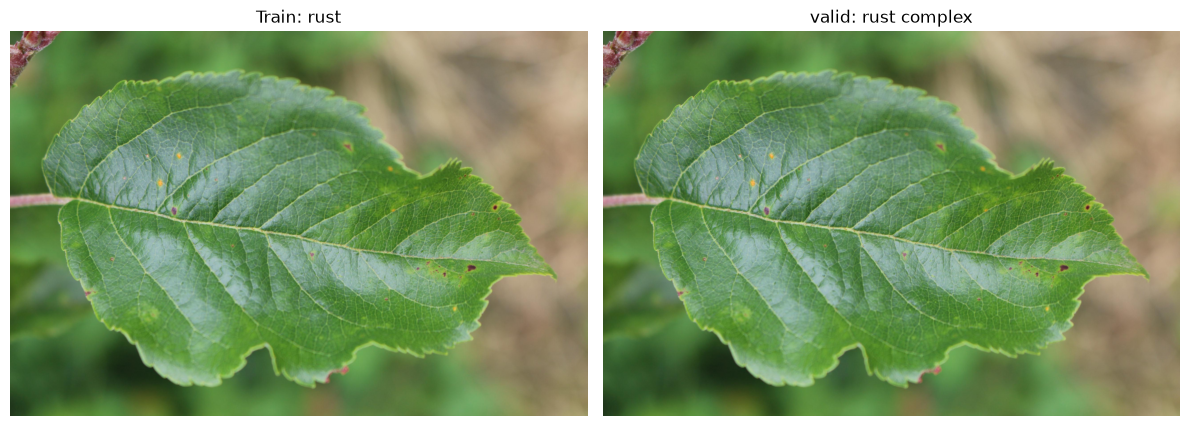

In [28]:
from PIL import Image
import matplotlib.pyplot as plt

train_path = DATA_DIR / "train_images" / sample["image_train"]
valid_path = DATA_DIR / "train_images" / sample["image_valid"]

train_image = Image.open(train_path).convert("RGB")
valid_image = Image.open(valid_path).convert("RGB")

fig, axes = plt.subplots(1, 2, figsize = (12, 5))

axes[0].imshow(train_image)
axes[0].set_title(f"Train: {sample['train_labels']}")
axes[0].axis("off")

axes[1].imshow(valid_image)
axes[1].set_title(f"valid: {sample['valid_labels']}")
axes[1].axis('off')

plt.tight_layout()
plt.show()

In [29]:
original_df = pd.read_csv(DATA_DIR / "train.csv")

filename = [
    sample["image_train"],
    sample["image_valid"]
]

display(
    original_df[
        original_df['image'].isin(filename)
    ]
)

,image,labels
410,82ba3e933947b097.jpg,rust complex
11165,cdf892b5b4865859.jpg,rust


In [30]:
original_df["hash"] = original_df["image"].map(all_hashes)

duplicates = original_df[
    original_df.duplicated("hash", keep = False)
].sort_values("hash")

print("중복 이미지 행 수:", len(duplicates))
print("중복 해시 그룹 수:", duplicates["hash"].nunique())

display(duplicates)

중복 이미지 행 수: 54
중복 해시 그룹 수: 27


,image,labels,hash
17113,f7d233d11aa8496c.jpg,rust,0fe3438d996e47c00d91c9d446b8ccc6da9418c1fb263a...
2557,94b42695f24dad36.jpg,complex,0fe3438d996e47c00d91c9d446b8ccc6da9418c1fb263a...
7703,b5ec52491e3349ce.jpg,rust,10b72c96dbb36395910659d434f80abd72b6b3553a4e09...
5078,a7e613159fb22859.jpg,rust complex,10b72c96dbb36395910659d434f80abd72b6b3553a4e09...
2124,90f99ee1c1132bb6.jpg,rust,13156fa77f8d57fd31486e73c24f3c8539f72dcc26f2a0...
2576,94c83b2d5fad6924.jpg,complex,13156fa77f8d57fd31486e73c24f3c8539f72dcc26f2a0...
16346,f2c798246a0a9bdd.jpg,rust,14e035e78a31a557eb1675d3fa2582850713cec4ff158a...
9411,c1a56069de75b899.jpg,complex,14e035e78a31a557eb1675d3fa2582850713cec4ff158a...
10731,ca782c131f5ce0fc.jpg,complex,17404b870e89eea102fe82dd28831ecf51143d7c6614ba...
14584,e5f27342ce1cb9a0.jpg,rust,17404b870e89eea102fe82dd28831ecf51143d7c6614ba...


In [31]:
group_sizes = duplicates.groupby("hash").size()

print(group_sizes.value_counts())

2    27
Name: count, dtype: int64


In [32]:
# EDA 결과

"""
Plant Pathology 2021의 학습 데이터 18,632개를 SHA-256으로 분석할 결과, 27개의 중복 이미지 그룹(총 54개 행)이 발견되었다.
각 그룹에 포함된 이미지의 라벨이 서로 다른 형상이 확인되었으며, 초기 Random Split에서는 그 중 12개 그룹이 Train과 Validation에 걸쳐 있음.
SHA-256기반 Group Split으로 교차 중복을 방지 했지만, 라벨 불일치는 별도로 검토
"""

'\nPlant Pathology 2021의 학습 데이터 18,632개를 SHA-256으로 분석할 결과, 27개의 중복 이미지 그룹(총 54개 행)이 발견되었다.\n각 그룹에 포함된 이미지의 라벨이 서로 다른 형상이 확인되었으며, 초기 Random Split에서는 그 중 12개 그룹이 Train과 Validation에 걸쳐 있음.\nSHA-256기반 Group Split으로 교차 중복을 방지 했지만, 라벨 불일치는 별도로 검토\n'

In [33]:
# 데이터 중복이 존재한다는 것과 Train/Validation 사이에 데이터 누수가 발생했다는 것은 서로 다른 문제

# 데이터 중복이 존재한다는 건
# 모델이 같은 이미지를 두 번 학습하게 됨
# 큰 문제는 아니지만, 특정 이미지가 학습 과정에서 더 큰 비중을 갖게 될 수 있음

# train/validation 사이에 데이터 누수가 있다는 것
# 모델이 train에서 학습한 것과 완전히 동일한 이미지를 validation에서 다시 만나는 것
# 즉, 모델 성능이 실제보다 좋게 측정될 가능성이 생김


In [34]:
classes = [
    "scab",
    "healthy",
    "frog_eye_leaf_spot",
    "complex",
    "rust",
    "powdery_mildew",
]

def multi_hot_encode(labels):
    label_list = labels.split()

    encoded = []

    for cls in classes:
        if cls in label_list:
            encoded.append(1)

        else:
            encoded.append(0)

    return encoded

In [35]:
print(multi_hot_encode("scab"))
print(multi_hot_encode("scab rust"))
print(multi_hot_encode("rust complex"))

[1, 0, 0, 0, 0, 0]
[1, 0, 0, 0, 1, 0]
[0, 0, 0, 1, 1, 0]


In [36]:
train_df['encoded_labels'] = train_df["labels"].apply(
    multi_hot_encode
)

display(train_df[["image", "labels", "encoded_labels"]].head())

,image,labels,encoded_labels
0,800113bb65efe69e.jpg,healthy,"[0, 1, 0, 0, 0, 0]"
1,8002cb321f8bfcdf.jpg,scab frog_eye_leaf_spot complex,"[1, 0, 1, 1, 0, 0]"
2,80070f7fb5e2ccaa.jpg,scab,"[1, 0, 0, 0, 0, 0]"
3,80077517781fb94f.jpg,scab,"[1, 0, 0, 0, 0, 0]"
4,800cbf0ff87721f8.jpg,complex,"[0, 0, 0, 1, 0, 0]"


In [37]:
import torch

labels = multi_hot_encode("scab rust")

target = torch.tensor(
    labels,
    dtype = torch.float32
)

print(target)
print(target.shape)

tensor([1., 0., 0., 0., 1., 0.])
torch.Size([6])


In [38]:
"""
정답 A: scab
정답 B: scab rust

[0.9, 0.1, 0.1, 0.1, 0.8, 0.1]

아마 모델은 정답 B에 더 가깝게 예측을 할것.
A를 가진 이미지는 라벨이 1개인데 2개로 예측되는 문제가 발생


그러면 Loss는 어떻게 계산?
모델이 정답 A에 대해 scab rust라고 잘못 예측했다면, 어떤 방식으로 모델에게 Rust의 예측 확률을 낮추라고 학습시킬 수 있나?

이것이 손실함수의 역할

우리가 사용하는 손실함수는 BCE(Binary Cross Entropy)
L = -[ylog(p) + (1-y)log(1-p)]
y: 실제 정답(0 또는 1)
p: 모델이 예측한 확률(0 과 1 사이)

상황 A : Scab 예측
실제 Scab이 존재하고, 모델은 0.9의 확률로 예측
y = 1
p = 0.9
L = -log(0.9) ~= 0.105

상황 B: Rust 예측
실제로 Rust는 없는데 모델은 0.8의 확률로 존재
y = 0
p = 0.8
L = -log(1-0.8) ~= 1.609

정답이 1일 때는 예측 확률이 높을수록 Loss가 작아지고, 정답이 0일 떄는 예측 확률이 낮을수록 Loss가 작아짐

이 원리를 이용해 모델이 올바른 방향으로 가중치를 업데이트하도록 학습을 시킴
"""

'\n정답 A: scab\n정답 B: scab rust\n\n[0.9, 0.1, 0.1, 0.1, 0.8, 0.1]\n\n아마 모델은 정답 B에 더 가깝게 예측을 할것.\nA를 가진 이미지는 라벨이 1개인데 2개로 예측되는 문제가 발생\n\n\n그러면 Loss는 어떻게 계산?\n모델이 정답 A에 대해 scab rust라고 잘못 예측했다면, 어떤 방식으로 모델에게 Rust의 예측 확률을 낮추라고 학습시킬 수 있나?\n\n이것이 손실함수의 역할\n\n우리가 사용하는 손실함수는 BCE(Binary Cross Entropy)\nL = -[ylog(p) + (1-y)log(1-p)]\ny: 실제 정답(0 또는 1)\np: 모델이 예측한 확률(0 과 1 사이)\n\n상황 A : Scab 예측\n실제 Scab이 존재하고, 모델은 0.9의 확률로 예측\ny = 1\np = 0.9\nL = -log(0.9) ~= 0.105\n\n상황 B: Rust 예측\n실제로 Rust는 없는데 모델은 0.8의 확률로 존재\ny = 0\np = 0.8\nL = -log(1-0.8) ~= 1.609\n\n정답이 1일 때는 예측 확률이 높을수록 Loss가 작아지고, 정답이 0일 떄는 예측 확률이 낮을수록 Loss가 작아짐\n\n이 원리를 이용해 모델이 올바른 방향으로 가중치를 업데이트하도록 학습을 시킴\n'

In [39]:
# 세 가지를 먼저 확인하는 습관을 들일것
# input.shape, target.shape, input.dtype, target.dtype

# 특히 BCEWithLogitsLoss 에서는 예측과 정답의 Shape이 같아야 하고, 정답은 float32같은 실수형 Tensor를 사용해야 함

# 

import torch 
import torch.nn as nn


probs = torch.tensor([
    [0.9, 0.1, 0.1, 0.1, 0.8, 0.1]
])

target = torch.tensor([
    [1., 0., 0., 0., 0., 0.]
])

logits = torch.logit(probs)

criterion = nn.BCEWithLogitsLoss()

loss = criterion(logits, target)

print("Loss:", loss.item())

Loss: 0.3560400903224945


In [40]:
# Gradient와 Backpropagation

# 지금 계산한 Loss값을 이해
# 예측확률이 [0.9, 0.1, 0.1, 0.1, 0.8, 0.1] 이고 정답이 [1., 0., 0., 0., 0., 0.]일 때, 
# Rust의 BCE Loss는 1.609 다른 클래스는 각각 0.105손실 따라서 평균 0.35604
# 전체 평균 Loss가 0.356으로 비교적 작아 보여도, 특정 클래스의 Loss는 1.609처럼 클 수 있음
# 이것이 나중에 클래스 별 Loss와 F1-score를 별도로 분석해야 하는 이유 중 하나

# BCE에서 Gradient가 계산되는 방법

import torch
import torch.nn as nn

# Rust가 존재하지 않는 이미지
target = torch.tensor([0.0])

# Rust와 예측 확률이 0.8이 되도록 Logit 설정
logits = torch.logit(
    torch.tensor([0.8])
).detach().requires_grad_(True)


criterion = nn.BCEWithLogitsLoss()

# 순전파
loss = criterion(logits, target)

loss.backward()

print('Loss:', loss.item())
print('Gradient:', logits.grad.item())

Loss: 1.6094380617141724
Gradient: 0.800000011920929


In [41]:
# Gradient를 이용해서 직접 업데이트를 함

# 현재 logit과 정답을 비교해 Loss 계산
# loss.backward()로 Gradient 계산
# Learning Rate를 사용해 Logit 업데이트
# zero_()로 기존 Gradient 초기화

criterion = nn.BCEWithLogitsLoss()

lr = 0.1

for epoch in range(10):
    loss = criterion(logits, target)

    loss.backward()

    with torch.no_grad():
        logits -= lr * logits.grad

    logits.grad.zero_()

    prob = torch.sigmoid(logits).item()

    print(
        f"Epoch {epoch + 1}:"
        f"Loss={loss.item():.4f},"
        f"Rust Prob={prob:.4f}"
    )

Epoch 1:Loss=1.6094,Rust Prob=0.7732
Epoch 2:Loss=1.4836,Rust Prob=0.7593
Epoch 3:Loss=1.4243,Rust Prob=0.7452
Epoch 4:Loss=1.3672,Rust Prob=0.7308
Epoch 5:Loss=1.3122,Rust Prob=0.7162
Epoch 6:Loss=1.2593,Rust Prob=0.7014
Epoch 7:Loss=1.2086,Rust Prob=0.6865
Epoch 8:Loss=1.1599,Rust Prob=0.6715
Epoch 9:Loss=1.1133,Rust Prob=0.6565
Epoch 10:Loss=1.0687,Rust Prob=0.6416


In [42]:
# Optimizer 와 Learning Rate

# Optimizer -> loss.backward()를 실행하면 Gradient가 계산됨
# 여기서 중요한 점은 loss.backward()는 가중치를 업데이트하지 않음
# gradient를 계산할 뿐
# 실제 가중치 업데이트는 Optimizer가 담당

# 이때 가중치를 얼마나 크게 변경할지 결정하는 중요한 하이퍼파라미터가 Learning Rate
# Learning Rate가 너무 작으면 학습이 느려질 수 있음
# Learning Rate가 너무 크면 최적값을 지나치거나 학습이 불안정할 수 있음
# 적절한 Learning Rate는 문제, 모델, Optimizer에 따라 달라짐

# 현재 가중치에서 계산된 Gradient를 이용해 가중치를 수정

# 가중치와 Gradient의 차이
# 가중치 :
    # 모델이 학습하는 파라미터
    # 입력을 이용해 예측값을 계산
    # 계산 방식: 학습 과정에서 업데이트

# Gradient:
    # 가중치 변화에 따른 Loss의 변화율
    # 가중치를 어느 방향으로 수정할지 알려줌
    # Loss를 가중치에 대해 미분


# 실제 숫자로 이해
# 손실함수: L(w) = (w - 3)^2
# Loss가 가장 작아지는 가중치는 w = 3
# 현재 가중치가 0이라고 가정

# 현재 가중치로 Loss 계산
# W = 0
# L(0) = (0 - 3)^2 = 9
# 현재 Loss는 9

# 현재 가중치에서 Gradient를 계산
# 손실함수를 가중치 w에 대해 미분하면,
# 2(w-3)
# 현재 가중치 w = 0을 대입하면 가중치가 0일때, Gradient는 -6

# gradient가 -6이라는 것은 가중치를 증가시키는 방향으로 움직이면 Loss가 감소한다는 것

# Gradient로 가중치 업데이트

# W_new = W_old - n(dL/dW)
# Learning Rate를 0.1로 설정하면, W_new = 0 - 0.1(-6) = 0.6
# 새로운 가중치는 0.6


In [43]:
import torch
w = torch.tensor([0.0], requires_grad=True)

loss = (w - 3) ** 2

loss.backward()

print("현재 가중치:", w.item())
print("Gradient:", w.grad.item())

with torch.no_grad():
    w -= 0.1 * w.grad

print("새로운 가중치:", w.item())
print("새로운 Loss:", ((w-3) ** 2).item())

현재 가중치: 0.0
Gradient: -6.0
새로운 가중치: 0.6000000238418579
새로운 Loss: 5.760000228881836


In [44]:
# PyTorch에서 직접 실험하기

import torch
import matplotlib.pyplot as plt

def train_sgd(ir, epochs = 20):
    w = torch.tensor([0.0], requires_grad=True)

    optimizer = torch.optim.SGD([w], lr = lr)

    history = []

    for epoch in range(epochs):
        optimizer.zero_grad()       # 이전 단계에서 계산한 Gradient를 초기화
                                    # pytorch에서는 기본적으로 Gradient가 누적되기 때문에 새로운 업데이트를 수행하기 전에 초기화 하는 것

        loss = (w - 3).pow(2).mean()

        loss.backward()             # gradient 계산
        optimizer.step()            # 계산된 gradient를 이용해 가중치 업데이트

        history.append(loss.item())

    return history

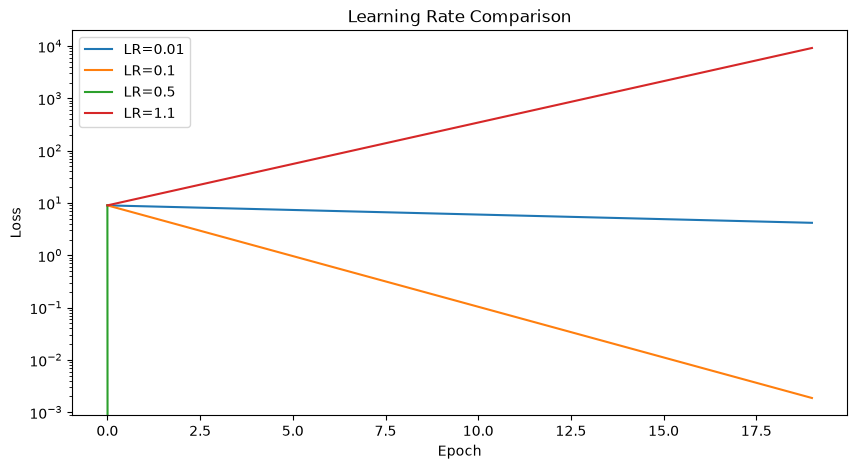

In [45]:
# 학습률별 Loss 비교

learning_rates = [0.01, 0.1, 0.5, 1.1]

plt.figure(figsize = (10, 5))

for lr in learning_rates:
    history = train_sgd(lr)

    plt.plot(history, label = f"LR={lr}")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Learning Rate Comparison")
plt.legend()
plt.yscale("log")
plt.show()

In [47]:
# SGD와 Adam의 다른 점

# SGD = 현재 Gradient를 기반으로 업데이트
# SGD + Momentum = 이전 업데이트 방향을 반영
# Adam = Gradient의 1차, 2차 모멘트를 이용해 적응적으로 업데이트
# AdamW = Adam의 적응적 업데이트와 분리된 Weight Decay 적용

In [49]:
# 지금까지는 가중치가 하나인 아주 간단한 예제
# 실제 모델들은 수많은 가중치가 있음


# z = w1x1 + w2x2 + b
# 이 경우 학습해야 하는 파라미터는 w1, w2, b 3개
# 역전파를 수행하면 각 파라미터에 대한 Gradient가 계산

# Optimizer는 이 Gradient들을 이용해 각 파라미터를 업데이트

# 즉, 모든 가중치가 같은 값으로 변겨오디는 게 아니라, 각 가중치의 Gradient에 따라 서로 다르게 업데이트

# 실제 신경망을 통해 가중치 업데이트 확인

import torch
import torch.nn as nn

torch.manual_seed(42)

# 입력 특성 2개 -> 출력 1개
model = nn.Linear(2, 1)

x = torch.tensor([[1.0, 2.0]])
y = torch.tensor([[1.0]])

criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr = 0.1)

print("업데이트 전 Weight")
print(model.weight.data)

# Forward
pred = model(x)
loss = criterion(pred, y)

# Backward
optimizer.zero_grad()
loss.backward()

print("\nWeight Gradient:")
print(model.weight.grad)

print("\nBias Gradient:")
print(model.bias.grad)

# 가중치 업데이트
optimizer.step()

print("\n 업데이트 후 WeightL")
print(model.weight.data)

업데이트 전 Weight
tensor([[0.5406, 0.5869]])

Weight Gradient:
tensor([[1.0975, 2.1951]])

Bias Gradient:
tensor([1.0975])

 업데이트 후 WeightL
tensor([[0.4309, 0.3674]])


In [50]:
print("입력값", x)

print("Weight:")
print(model.weight)

print("Weight Gradient:")
print(model.weight.grad)

print("Gradient 비율:")
print(
    model.weight.grad[0][1] /
    model.weight.grad[0][0]
)

입력값 tensor([[1., 2.]])
Weight:
Parameter containing:
tensor([[0.4309, 0.3674]], requires_grad=True)
Weight Gradient:
tensor([[1.0975, 2.1951]])
Gradient 비율:
tensor(2.)


In [51]:
import torch

w = torch.tensor([0.0], requires_grad=True)

lr = 1.5

for epoch in range(10):
    loss = (w - 3).pow(2).mean()
    loss.backward()

    old_loss = loss.item()
    grad = w.grad.detach().clone()

    current_lr = lr

    with torch.no_grad():
        while True:
            new_w = w - current_lr * grad
            new_loss = (new_w - 3).pow(2).mean()

            if new_loss.item() <= old_loss:
                w.copy_(new_w)
                break

            current_lr *= 0.5

    w.grad =  None

    print(
        f"Epoch {epoch+1} | "
        f"Loss {new_loss.item():.4f} | "
        f"Weight {w.item():.4f} | "
        f"LR {current_lr:.4f} | "
    )

Epoch 1 | Loss 2.2500 | Weight 4.5000 | LR 0.7500 | 
Epoch 2 | Loss 0.5625 | Weight 2.2500 | LR 0.7500 | 
Epoch 3 | Loss 0.1406 | Weight 3.3750 | LR 0.7500 | 
Epoch 4 | Loss 0.0352 | Weight 2.8125 | LR 0.7500 | 
Epoch 5 | Loss 0.0088 | Weight 3.0938 | LR 0.7500 | 
Epoch 6 | Loss 0.0022 | Weight 2.9531 | LR 0.7500 | 
Epoch 7 | Loss 0.0005 | Weight 3.0234 | LR 0.7500 | 
Epoch 8 | Loss 0.0001 | Weight 2.9883 | LR 0.7500 | 
Epoch 9 | Loss 0.0000 | Weight 3.0059 | LR 0.7500 | 
Epoch 10 | Loss 0.0000 | Weight 2.9971 | LR 0.7500 | 


In [53]:
# SGD, Adam, AdamW는 무엇이 다를까?
# 세 Optimizer 모두 Loss를 줄이는 방향으로 가중치를 업데이트하려는 알고리즘이지만, Gradient를 활용하는 방식이 다름

# SGD = 현재 Gradient 사용, 특징: 단순하고 직관적
# Adam = Gradient의 과거 정보 활용, 특징: 파라미터별 적응적 업데이트
# AdamW = Adam + 분리된 Weight Decay, 특징: 정규화를 독립적으로 적용

# SGD: 현재 Gradient를 이용
# 실제 신경망의 Loss는 매우 복잡하기 때문에 Gradient 방향이 매번 크게 달라질 수 있음
# 그렇다면 이전에 이동하던 방향도 함께 고려하면 어떨까?

# Momentum: 이전 업데이트 방향을 기억한다.

# Momentum은 과거 Gradient의 정보를 누적해서 활용
# Momentum의 수식에서 베타(B)는 과거 정보를 얼마나 유지할지 결정하는 값
# 예를 들어 베타가 0.9라면 이전에 누적된 방향의 90%를 유지하면서 현재 Gradient를 더함
# 그 결과 일관된 방향의 이동을 가속하고, Gradient가 번갈아 바뀌는 방향의 진동을 완화할 수 있음

# Adam: 방향과 크기를 적응적으로 조정
# Adam은 크게 두 가지 정보를 활용

# 1차 모멘트: Gradient의 지수이동평균
# 2차 모멘트: Gradient 제곱의 지수이동평균

# Adam은 여기에 초기 편향 보정을 적용한 mt, vt를 이용해 가중치를 업데이트

# 즉, 모든 가중치에 같은 Learning Rate를 적용하더라도 실제 업데이트 크기는 파라미터마다 달라질 수 있음

# 이게 SGD과 Adam의 중요한 차이

# AdamW와 Adam의 다른점

# AdamW에서 W는 Weight Decay를 의미
# Weight Decay는 가중치가 지나치게 커지는 것을 억제하는 정규화 방법
# AdamW는 Adam의 Gradient 기반 업데이트와 Weight Dacay를 분리해 적용

# 여기서 람다는 Weight Decay의 강도를 결정
# 중요한 점은 AdamW가 Adam보다 항상 성능이 좋은 것은 아님
# 다만 신경망 학습에서 Weight Decay를 제어하기 편리하기 때문에 널리 사용되는 Optimzier중 하나

# 실제 코드

optimizer = torch.optim.SGD(
    model.parameters(),
    lr = 0.01
)

optimizer = torch.optim.SGD(
    model.parameters(),
    lr = 0.01,
    momentum=0.9
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr = 0.001
)

optimzier = torch.optim.AdamW(
    model.parameters(),
    lr = 0.001,
    weight_decay=0.01
)

# 각 Optimizer에 동일한 Learning Rate를 적용해서 비교하는 것이 반드시 공정한 비교가 아님
# Optimizer마다 적절한 Learninng Rate 범위가 다르기 때문
# 실제 실험에서는 동일한 모델, 데이터 분할, 평가지표를 사용하되 각 Optimizer의 Learning Rate를 적절하게 탐색해야 됨

In [54]:
import torch
import matplotlib.pyplot as plt

def run_optimizer(optimizer_name, lr, epochs = 100):
    w = torch.tensor([3.0, 3.0], requires_grad=True)

    if optimizer_name == "SGD":
        optimizer = torch.optim.SGD([w], lr = lr)

    elif optimizer_name == "Adam":
        optimizer = torch.optim.Adam([w], lr = lr)

    elif optimizer_name == "AdamW":
        optimizer = torch.optim.AdamW(
            [w],
            lr = lr,
            weight_decay = 0.01
        )

    history = []

    for epoch in range(epochs):
        optimizer.zero_grad()

        loss = 10 * w[0]**2 + w[1]**2

        loss.backward()
        optimizer.step()

        history.append(loss.item())

    return history

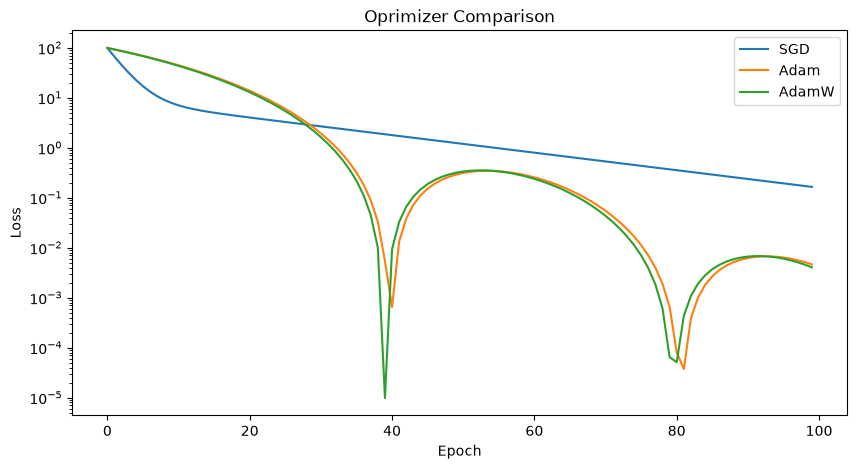

In [55]:
experiments = {
    "SGD": 0.01,
    "Adam": 0.1,
    "AdamW": 0.1
}

plt.figure(figsize = (10, 5))

for name, lr in experiments.items():
    history = run_optimizer(name, lr)

    plt.plot(history, label = name)


plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Oprimizer Comparison")
plt.legend()
plt.yscale("log")
plt.show()

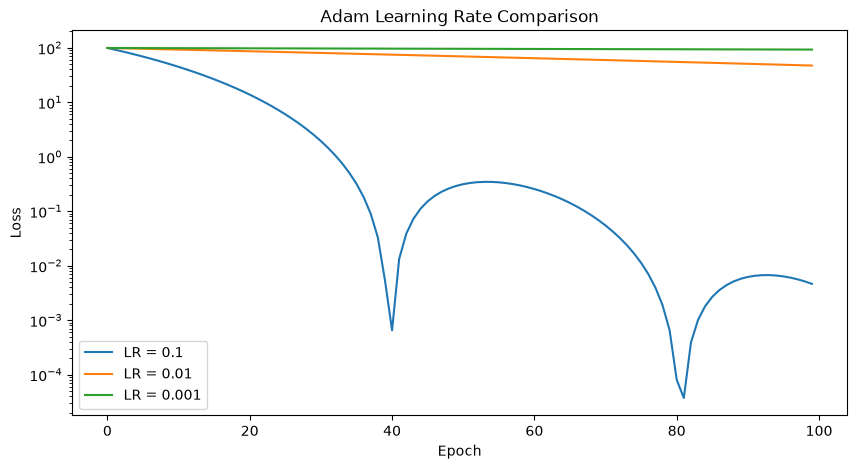

In [56]:
learning_rates = [0.1, 0.01, 0.001]

plt.figure(figsize = (10, 5))

for lr in learning_rates:
    history = run_optimizer("Adam", lr, epochs = 100)

    plt.plot(history, label = f"LR = {lr}")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title('Adam Learning Rate Comparison')
plt.legend()
plt.yscale("log")
plt.show()

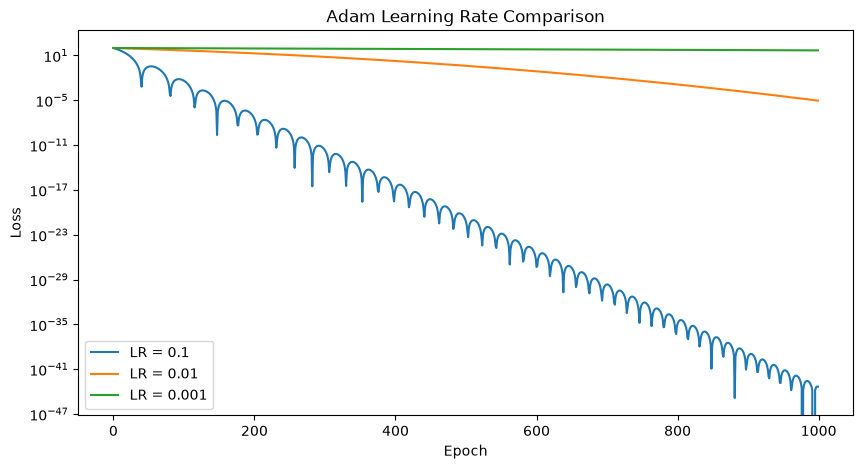

In [59]:
learning_rates = [0.1, 0.01, 0.001]

plt.figure(figsize = (10, 5))

for lr in learning_rates:
    history = run_optimizer("Adam", lr, epochs = 1000)

    plt.plot(history, label = f"LR = {lr}")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title('Adam Learning Rate Comparison')
plt.legend()
plt.yscale("log")
plt.show()

In [ ]:
import torch
import matplotlib.pyplot as plt

def train_with_scheduler(epochs = 1000):
    w = torch.tensor([3.0, 3.0], requires_grad=True)

    optimizer = torch.optim.Adam([w], lr = 0.1)

    # 200 Epoch마다, Learning rate를 절반으로 줄임
    scheduler = torch.optim.lr_scheduler.StepLR(
        optimizer,
        step_size = 200,
        gamma = 0.5
    )

    losses = []
    learning_rates = []

    for epoch in range(epochs):
        optimizer.zero_grad()

        loss = 10 * w[0]**2 + w[1]**2

        loss.backward()
        optimizer.step()

        losses.append(loss.item())
        learning_rates.append(optimzier.param_groups[0]["lr"])

        scheduler.step()

    return losses, learning_rates

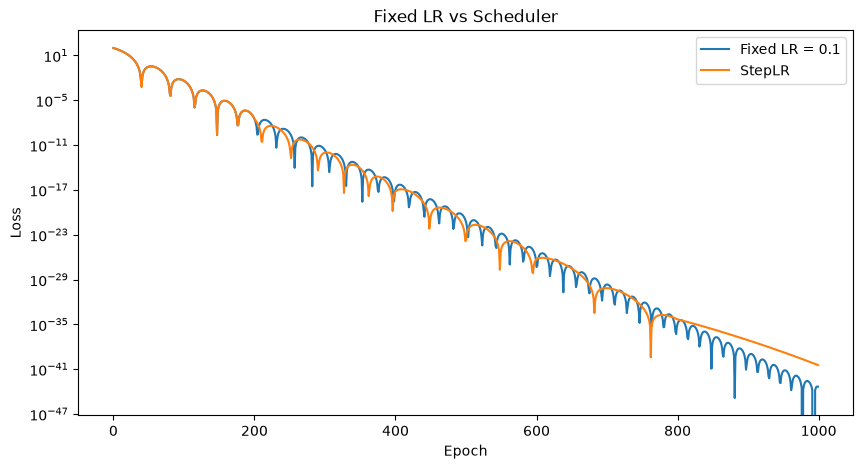

In [62]:
# 고정 learning rate 와 scheduler 비교

fixed_loss = run_optimizer(
    "Adam",
    lr = 0.1,
    epochs = 1000
)

scheduler_loss, lr_history = train_with_scheduler(
    epochs = 1000
)

plt.figure(figsize = (10, 5))
plt.plot(fixed_loss, label = "Fixed LR = 0.1")
plt.plot(scheduler_loss, label = "StepLR")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.yscale("log")
plt.legend()
plt.title("Fixed LR vs Scheduler")
plt.show()